# 03 - Keyword Prediction Baseline

Loads `clean_articles.pkl` (output of `02_cleaning_eda`).
Pipeline: TF-IDF → MultiLabelBinarizer → OneVsRestClassifier (LogisticRegression).

Target column: `keywords_filtered` (set by EDA notebook, min_freq=10, no OCIS codes).

In [2]:
#!pip install scikit-learn

import numpy as np
import pandas as pd
import re
from pathlib import Path
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report
import matplotlib.pyplot as plt

CWD = Path.cwd()
PROJECT_ROOT = CWD if (CWD / 'big_data').exists() else CWD.parent

df = pd.read_pickle(PROJECT_ROOT / 'big_data' / 'baseline' / 'pickle' / 'clean_articles.pkl')
print(f"Loaded: {df.shape[0]} articles, {df.shape[1]} columns")
df.columns

Loaded: 34128 articles, 20 columns


Index(['filename', 'pmcid', 'doi', 'journal', 'year', 'authors', 'title',
       'keywords', 'abstract', 'introduction', 'methods', 'results',
       'discussion', 'conclusion', 'tables', 'metadata_junk', 'kwd_lst',
       'kwd_lst_cl', 'n_keywords', 'keywords_filtered'],
      dtype='str')

## 1 - Feature & Target Preparation

In [3]:
# Input: title + abstract concatenated
df['text'] = df['title'].fillna('') + ' ' + df['abstract'].fillna('') #+ ' ' + df['introduction'].fillna('')

# Target: keywords_filtered (list of valid keywords per article)
# MultiLabelBinarizer -> binary matrix (n_articles, n_keywords)
mlb = MultiLabelBinarizer()
y = mlb.fit_transform(df['keywords_filtered'])

print(f"Classes (unique keywords): {len(mlb.classes_)}")
print(f"y shape                 : {y.shape}")
print(f"Avg keywords per article: {y.sum(axis=1).mean():.1f}")

Classes (unique keywords): 2749
y shape                 : (34128, 2749)
Avg keywords per article: 2.3


## 2 - Train/Test Split

In [4]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['text'], y,
    test_size=0.2,
    random_state=42
)
print(f"Train: {len(X_train_raw)} | Test: {len(X_test_raw)}")

Train: 27302 | Test: 6826


## 3 - TF-IDF Vectorizer

In [5]:
tfidf = TfidfVectorizer(
    max_features=50_000,
    ngram_range=(1, 2),    # unigrams + bigrams
    sublinear_tf=True,     # log(1+tf) dampening
    min_df=5               # ignore very rare terms
)

X_train = tfidf.fit_transform(X_train_raw)
X_test  = tfidf.transform(X_test_raw)

print(f"Feature matrix train: {X_train.shape}")
print(f"Feature matrix test : {X_test.shape}")
#51.6sec

Feature matrix train: (27302, 50000)
Feature matrix test : (6826, 50000)


## 4 - Train Baseline Model

In [6]:
clf = OneVsRestClassifier(
    LogisticRegression(max_iter=1000, C=0.1),
    n_jobs=-1   # use all cores
)
clf.fit(X_train, y_train)
print("Training done.")

Training done.


## 5 - Threshold Tuning

In [7]:
# predict_proba -> score per keyword per article
proba = clf.predict_proba(X_test)

# Scan thresholds, pick best micro-F1
thresholds = [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5]
results = []
for t in thresholds:
    y_pred = (proba >= t).astype(int)
    f1_micro = f1_score(y_test, y_pred, average='micro', zero_division=0)
    f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
    n_avg    = y_pred.sum(axis=1).mean()
    results.append({'threshold': t, 'f1_micro': f1_micro, 'f1_macro': f1_macro, 'avg_labels': n_avg})
    print(f"t={t:.2f}  micro-F1={f1_micro:.3f}  macro-F1={f1_macro:.3f}  avg_labels={n_avg:.1f}")

df_res = pd.DataFrame(results)
best_t = df_res.loc[df_res['f1_micro'].idxmax(), 'threshold']
print(f"\nBest threshold: {best_t}")

t=0.10  micro-F1=0.001  macro-F1=0.000  avg_labels=0.0
t=0.15  micro-F1=0.000  macro-F1=0.000  avg_labels=0.0
t=0.20  micro-F1=0.000  macro-F1=0.000  avg_labels=0.0
t=0.25  micro-F1=0.000  macro-F1=0.000  avg_labels=0.0
t=0.30  micro-F1=0.000  macro-F1=0.000  avg_labels=0.0
t=0.35  micro-F1=0.000  macro-F1=0.000  avg_labels=0.0
t=0.40  micro-F1=0.000  macro-F1=0.000  avg_labels=0.0
t=0.50  micro-F1=0.000  macro-F1=0.000  avg_labels=0.0

Best threshold: 0.1


## 6 - Final Evaluation

Micro-F1 : 0.001
Macro-F1 : 0.000


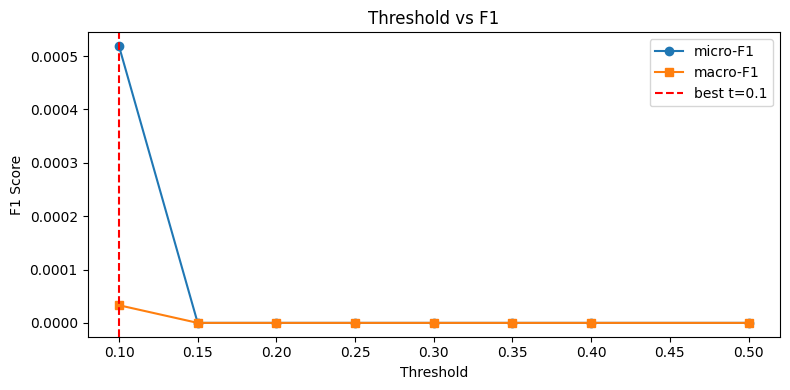

In [ ]:
y_pred_best = (proba >= best_t).astype(int)

print(f"Micro-F1 : {f1_score(y_test, y_pred_best, average='micro', zero_division=0):.3f}")
print(f"Macro-F1 : {f1_score(y_test, y_pred_best, average='macro', zero_division=0):.3f}")

# F1 curve plot
plt.figure(figsize=(8, 4))
plt.plot(df_res['threshold'], df_res['f1_micro'], marker='o', label='micro-F1')
plt.plot(df_res['threshold'], df_res['f1_macro'], marker='s', label='macro-F1')
plt.axvline(best_t, color='red', linestyle='--', label=f'best t={best_t}')
plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('Threshold vs F1')
plt.legend()
plt.tight_layout()
plt.show()

plt.savefig("plots/f1_threshold_baseline0.png", dpi=150, bbox_inches='tight')
#Micro-F1 : 0.205
#Macro-F1 : 0.031

## 7 - Example Predictions

In [11]:
# Show 5 example predictions vs ground truth
sample_idx = np.arange(100,105)
for i in sample_idx:
    true_kws = mlb.inverse_transform(y_test[i:i+1])[0]
    pred_kws = mlb.inverse_transform(y_pred_best[i:i+1])[0]
    print(f"--- Article {i} ---")
    print(f"  TRUE : {sorted(true_kws)}")
    print(f"  PRED : {sorted(pred_kws)}")
    print()

--- Article 100 ---
  TRUE : ['decision making', 'evidence based medicine', 'guideline']
  PRED : []

--- Article 101 ---
  TRUE : ['angiogenesis', 'immunotherapy', 'mtor', 'survival', 'targeted therapy']
  PRED : []

--- Article 102 ---
  TRUE : ['cone beam computed tomography', 'dental implants']
  PRED : []

--- Article 103 ---
  TRUE : ['patient safety']
  PRED : []

--- Article 104 ---
  TRUE : ['anti bacterial agents', 'neutropenia', 'renal insufficiency']
  PRED : []



## 8 - Save Model (optional)

In [10]:
SAVE_MODEL = True  # set True to persist

if SAVE_MODEL:
    import pickle
    model_dir = PROJECT_ROOT / 'models'
    model_dir.mkdir(exist_ok=True)
    with open(model_dir / 'baseline_clf.pkl', 'wb') as f:
        pickle.dump({'clf': clf, 'tfidf': tfidf, 'mlb': mlb, 'threshold': best_t}, f)
    print(f"Saved to {model_dir / 'baseline_clf.pkl'}")
else:
    print("SAVE_MODEL = False - nothing written.")

Saved to c:\Users\<user>\bootcamps\CAPSTONE\Capstone1-text-prediction-for-scientific-papers\models\baseline_clf.pkl


**METRICS**

*F1 scoring* - harmonic mean of precision and recall -> balances both metrics
- micro-F1: frequqnt keywrods prediction 
- macro-F1: mean of all F1 of each keyword -> rare kwds having poor F1 pull avg F1 down extremely 

| Experiment | micro-F1 | macro-F1 | Conclusion |
|------------|----------|----------|-------|
| title+abstract, C=1.0 | 0.205 | 0.031 | **Baseline** |
| title+abstract+intro, C=0.1 | 0.006 | 0.000 | C=0.1 reulgarization too extreme |


- very bad F1 scoring
- MultiLabelBinarizer uses >3000 keywords in lists as a target -> will be transfrmed into ca 3000 binary target columns with extreme sparcity (for "min_freq", 10 minimal frequencies was chosen -> e.g. 11 positive vs 19000 negative cases -> extreme imbalance )
- hence: model says almost always "0"

**change to Transformer (BioBERT)**
- 20k Articles , 3000 classes -> CPU: Vectorizing ~3-8h + Training~10-24h
- 20k Articles , 3000 classes -> GPU (Googe colab T4) Encoding~20-40min, Training (3 epochs): 1-3 h